# 06 - Evaluation, Explainability & Sensitivity (Member 4 - Kasuntha S.M.M.)
**Project:** ML-based prediction of cardio-metabolic risk (metabolic syndrome) from NHANES 2011-2014 wrist-accelerometer data.

| Task | What this notebook does | Output |
|---|---|---|
| **M4-01** | Accuracy, precision, recall, F1, balanced accuracy on the held-out test set | `reports/tables/model_performance_metrics.csv` |
| **M4-02** | ROC-AUC, PR-AUC, Brier score (+ DeLong tests) | same table, `statistical_tests.csv` |
| **M4-03** | ROC / PR curves, confusion matrices, calibration curves | `reports/figures/m4_03_*.png` |
| **M4-04** | 95% bootstrap CIs (B = 1000) and paired Set 0 -> A -> B differences | `model_performance_metrics.csv`, `m4_04_*.png` |
| **M4-05** | LR odds ratios, RF Gini importance, permutation importance, selection stability | `feature_importance_*.csv`, `m4_05_*.png` |
| **M4-06** | E4: refit with fasting survey weights `WTSAF2YR / 2` | `sensitivity_analysis_results.csv` |
| **M4-07** | E5: cross-cycle transfer; E6: feature-group ablation | same table, `m4_07_sensitivity.png` |
| **M4-08** | Integration: summary of findings for the report | Section 9 |

**Inputs (from Member 3):** `data/processed/test_predictions.parquet`, `cv_results_summary.parquet`, feature sets from Member 2.
**Leakage rules:** thresholds come from out-of-fold *training* predictions (Member 3); the test set is only *scored* here.
E5 re-tunes inside the training cycle, and E6 uses training-set CV only, so no hyperparameter is chosen on test data.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "src" / "evaluation").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

from src.evaluation import bootstrap, explainability as xai, metrics, plots, sensitivity
from src.models.pipeline import FEATURE_SET_FILES, load_feature_set

FIGS = ROOT / "reports" / "figures"
TABLES = ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

preds = pd.read_parquet(ROOT / "data" / "processed" / "test_predictions.parquet")
cv_summary = xai.load_cv_summary()

SETS = list(FEATURE_SET_FILES)                       # ['Set 0', 'Set A', 'Set B']
MODELS = list(dict.fromkeys(preds.model))            # order used by Member 3
data = {s: load_feature_set(s) for s in SETS}        # X_train, X_test, y_train, y_test

print("Models :", MODELS)
print("Sets   :", SETS)
print("Test predictions:", preds.shape, "| test participants:", preds.SEQN.nunique(),
      "| prevalence:", round(preds.drop_duplicates("SEQN").y_true.mean(), 3))

Models : ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
Sets   : ['Set 0', 'Set A', 'Set B']
Test predictions: (8262, 6) | test participants: 918 | prevalence: 0.429


## 2. Fitted pipelines + reproducibility check
Member 3's fitted pipelines live in `models/tuned_pipelines.joblib`, which is **git-ignored** (shared via Google Drive).
- If the file is present, it is loaded.
- If not (or if the pickle was made with another scikit-learn version and cannot load), every pipeline is
  **rebuilt** from Member 3's saved best hyperparameters (`cv_results_summary.parquet`), refitted on the same
  training rows with the same seed, and saved to `models/tuned_pipelines.joblib` in Member 3's format.

Either way the pipelines must give the **same test probabilities** as Member 3's handover file
(`test_predictions.parquet`). The assert below stops the notebook if they do not.

In [2]:
pipes, source = xai.load_or_rebuild_pipelines(data, ROOT / "models" / "tuned_pipelines.joblib")
print("Pipelines:", source)

rows = []
for (s, m), pipe in pipes.items():
    X_test = data[s][1]
    handover = preds[(preds.feature_set == s) & (preds.model == m)].set_index("SEQN")
    p_new = pd.Series(pipe.predict_proba(X_test)[:, 1], index=X_test.index)
    rows.append({"feature_set": s, "model": m,
                 "max_abs_diff": (p_new - handover.loc[X_test.index, "y_proba"]).abs().max()})
repro = pd.DataFrame(rows)
display(repro)
assert len(repro) == len(cv_summary), "a (feature set, model) pipeline is missing"
assert (repro.max_abs_diff < 1e-6).all(), "pipelines do not reproduce Member 3's test predictions"
print(f"All {len(repro)} pipelines reproduce Member 3's test predictions exactly.")

Pipelines: loaded tuned_pipelines.joblib


,feature_set,model,max_abs_diff
0,Set 0,Logistic Regression,0.000e+00
1,Set 0,Random Forest,2.220e-16
2,Set 0,Gradient Boosting,0.000e+00
3,Set A,Logistic Regression,0.000e+00
4,Set A,Random Forest,1.110e-16
5,Set A,Gradient Boosting,0.000e+00
6,Set B,Logistic Regression,0.000e+00
7,Set B,Random Forest,2.220e-16
8,Set B,Gradient Boosting,0.000e+00


All 9 pipelines reproduce Member 3's test predictions exactly.


## 3. Test-set metrics (M4-01, M4-02)
Two thresholds are reported:
- **tau = 0.5** (default), and
- **tau_F1**, chosen by Member 3 to maximise F1 on out-of-fold *training* predictions (proposal 4.8). This is the primary operating point.

A **majority-class baseline** (always predicts the training prevalence) anchors the lower bound.

In [3]:
tau_f1 = cv_summary.set_index(["feature_set", "model"]).threshold_f1

point_rows = []
for s in SETS:
    for m in MODELS:
        g = preds[(preds.feature_set == s) & (preds.model == m)]
        for name, tau in [("tau_0.5", 0.5), ("tau_F1", tau_f1[(s, m)])]:
            point_rows.append({"feature_set": s, "model": m, "threshold": name, "tau": tau,
                               **metrics.classification_metrics(g.y_true, g.y_proba, tau)})

# Majority-class baseline: constant probability = training prevalence
y_tr, y_te = data["Set B"][2], data["Set B"][3]
base = metrics.classification_metrics(y_te, np.full(len(y_te), y_tr.mean()), 0.5)
point_rows.append({"feature_set": "-", "model": "Majority-class baseline", "threshold": "tau_0.5",
                   "tau": 0.5, **base})
point = pd.DataFrame(point_rows)
display(point[point.threshold == "tau_F1"].drop(columns="threshold").set_index(["feature_set", "model"]))

tau  accuracy  precision  recall     f1  balanced_accuracy  roc_auc  pr_auc  brier
feature_set model                                                                                                    
Set 0       Logistic Regression  0.377     0.634      0.547   0.855  0.667              0.661    0.732   0.609  0.211
            Random Forest        0.360     0.632      0.544   0.873  0.671              0.662    0.726   0.613  0.211
            Gradient Boosting    0.385     0.670      0.589   0.766  0.666              0.682    0.733   0.642  0.207
Set A       Logistic Regression  0.388     0.669      0.577   0.858  0.690              0.692    0.751   0.630  0.206
            Random Forest        0.443     0.671      0.590   0.764  0.666              0.683    0.743   0.649  0.206
            Gradient Boosting    0.352     0.664      0.579   0.797  0.671              0.681    0.751   0.659  0.200
Set B       Logistic Regression  0.396     0.672      0.582   0.840  0.687              0.693    0.761   0.645  0.201
            Random Forest        0.387     0.653      0.565   0.825  0.671              0.674    0.744   0.650  0.206
            Gradient Boosting    0.346     0.671      0.585   0.807  0.678              0.688    0.754   0.665  0.199

## 4. 95% bootstrap confidence intervals (M4-04)
The 918 test participants are resampled with replacement **1,000 times** (same resamples for every model).
Percentile CIs are reported for every metric and both thresholds.

In [4]:
ci_rows = []
for s in SETS:
    for m in MODELS:
        g = preds[(preds.feature_set == s) & (preds.model == m)]
        for name, tau in [("tau_0.5", 0.5), ("tau_F1", tau_f1[(s, m)])]:
            ci = bootstrap.bootstrap_metrics(g.y_true.to_numpy(), g.y_proba.to_numpy(), tau)
            ci_rows.append(ci.rename_axis("metric").reset_index()
                           .assign(feature_set=s, model=m, threshold=name, tau=tau))
metrics_long = pd.concat(ci_rows, ignore_index=True)[
    ["feature_set", "model", "threshold", "tau", "metric", "estimate", "ci_low", "ci_high"]]
metrics_long.to_csv(TABLES / "model_performance_metrics.csv", index=False)

# Readable wide table: "estimate [low, high]" at the F1 threshold
fmt = metrics_long[metrics_long.threshold == "tau_F1"].assign(
    value=lambda d: d.apply(lambda r: f"{r.estimate:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1))
summary_table = (fmt.pivot(index=["feature_set", "model"], columns="metric", values="value")
                 [metrics.METRIC_NAMES])
summary_table.to_csv(TABLES / "model_performance_summary.csv")
display(summary_table)

metric                                       accuracy             precision                recall                    f1     balanced_accuracy  \
feature_set model                                                                                                                               
Set 0       Gradient Boosting    0.670 [0.643, 0.700]  0.589 [0.552, 0.630]  0.766 [0.725, 0.809]  0.666 [0.633, 0.701]  0.682 [0.655, 0.712]   
            Logistic Regression  0.634 [0.605, 0.665]  0.547 [0.512, 0.584]  0.855 [0.818, 0.888]  0.667 [0.636, 0.700]  0.661 [0.634, 0.688]   
            Random Forest        0.632 [0.601, 0.660]  0.544 [0.508, 0.581]  0.873 [0.839, 0.904]  0.671 [0.636, 0.702]  0.662 [0.635, 0.687]   
Set A       Gradient Boosting    0.664 [0.636, 0.695]  0.579 [0.542, 0.620]  0.797 [0.754, 0.838]  0.671 [0.638, 0.704]  0.681 [0.653, 0.710]   
            Logistic Regression  0.669 [0.641, 0.698]  0.577 [0.542, 0.615]  0.858 [0.821, 0.893]  0.690 [0.658, 0.722]  0.692 [0.665, 0.720]   
            Random Forest        0.671 [0.643, 0.703]  0.590 [0.552, 0.631]  0.764 [0.718, 0.809]  0.666 [0.631, 0.702]  0.683 [0.654, 0.714]   
Set B       Gradient Boosting    0.671 [0.643, 0.699]  0.585 [0.547, 0.625]  0.807 [0.764, 0.848]  0.678 [0.643, 0.711]  0.688 [0.660, 0.716]   
            Logistic Regression  0.672 [0.645, 0.704]  0.582 [0.544, 0.622]  0.840 [0.799, 0.877]  0.687 [0.655, 0.721]  0.693 [0.666, 0.721]   
            Random Forest        0.653 [0.624, 0.685]  0.565 [0.528, 0.605]  0.825 [0.783, 0.863]  0.671 [0.637, 0.706]  0.674 [0.646, 0.703]   

metric                                        roc_auc                pr_auc                 brier  
feature_set model                                                                                  
Set 0       Gradient Boosting    0.733 [0.702, 0.765]  0.642 [0.594, 0.697]  0.207 [0.195, 0.218]  
            Logistic Regression  0.732 [0.700, 0.763]  0.609 [0.559, 0.666]  0.211 [0.199, 0.222]  
            Random Forest        0.726 [0.696, 0.759]  0.613 [0.568, 0.669]  0.211 [0.200, 0.222]  
Set A       Gradient Boosting    0.751 [0.722, 0.784]  0.659 [0.612, 0.715]  0.200 [0.187, 0.211]  
            Logistic Regression  0.751 [0.720, 0.784]  0.630 [0.581, 0.686]  0.206 [0.193, 0.217]  
            Random Forest        0.743 [0.712, 0.776]  0.649 [0.602, 0.707]  0.206 [0.194, 0.218]  
Set B       Gradient Boosting    0.754 [0.725, 0.787]  0.665 [0.620, 0.722]  0.199 [0.187, 0.211]  
            Logistic Regression  0.761 [0.730, 0.793]  0.645 [0.599, 0.701]  0.201 [0.189, 0.213]  
            Random Forest        0.744 [0.715, 0.780]  0.650 [0.606, 0.706]  0.206 [0.194, 0.218]

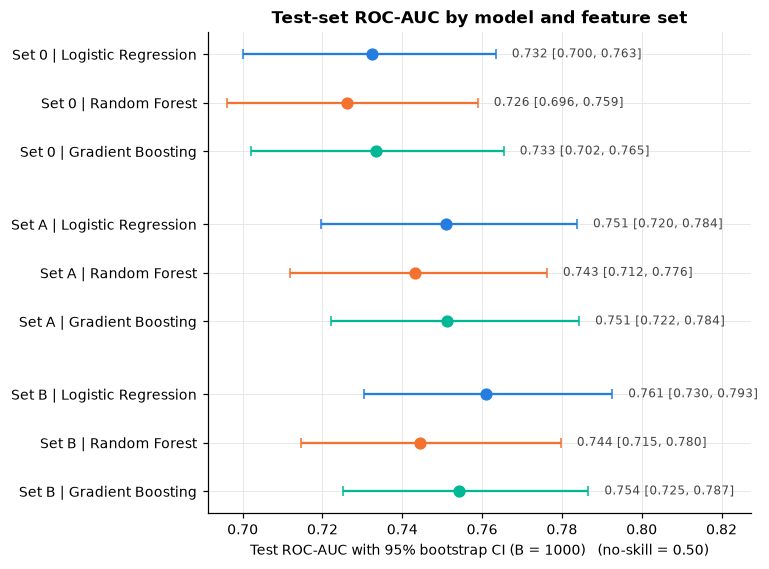

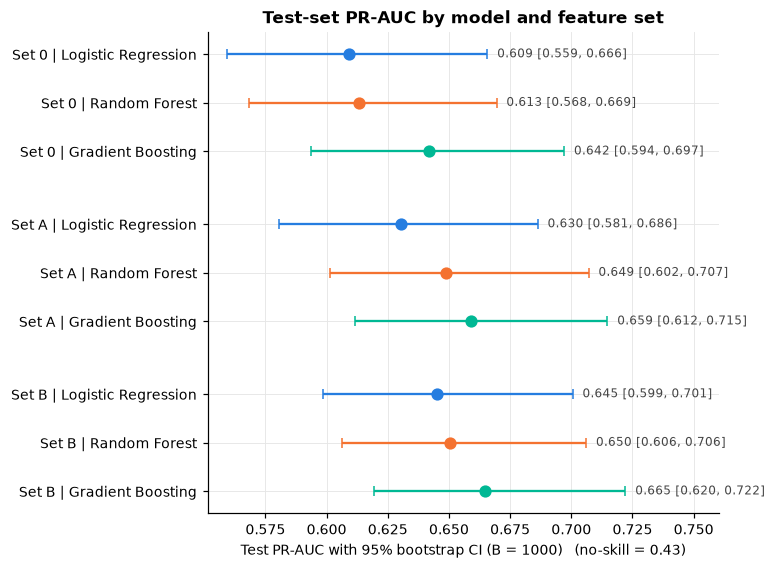

In [5]:
fig = plots.plot_metric_forest(metrics_long[metrics_long.threshold == "tau_F1"], "roc_auc",
                               MODELS, SETS, baseline=0.5)
plots.save(fig, FIGS / "m4_04_roc_auc_forest_plot.png"); plt.show()

fig = plots.plot_metric_forest(metrics_long[metrics_long.threshold == "tau_F1"], "pr_auc",
                               MODELS, SETS, baseline=y_te.mean())
plots.save(fig, FIGS / "m4_04_pr_auc_forest_plot.png"); plt.show()

### 4.1 RQ2 - does wearable data add value? (paired tests)
For each model, the **same test participants** are scored with Set 0, A and B. Two complementary tests:
- **Paired bootstrap** of the ROC-AUC difference (95% CI; significant if the CI excludes 0).
- **DeLong test** for correlated ROC curves (proposal 4.8).

The same two tests also compare every model against the best model within each feature set (RQ1).

In [6]:
def proba(s, m):
    return preds[(preds.feature_set == s) & (preds.model == m)].sort_values("SEQN")

test_rows = []
for m in MODELS:
    for a, b in [("Set 0", "Set A"), ("Set A", "Set B"), ("Set 0", "Set B")]:
        ga, gb = proba(a, m), proba(b, m)
        assert (ga.SEQN.to_numpy() == gb.SEQN.to_numpy()).all()
        boot = bootstrap.paired_bootstrap_difference(ga.y_true.to_numpy(), ga.y_proba.to_numpy(), gb.y_proba.to_numpy())
        dl = metrics.delong_test(ga.y_true.to_numpy(), gb.y_proba.to_numpy(), ga.y_proba.to_numpy())
        test_rows.append({"comparison": "feature sets", "model": m, "a": a, "b": b,
                          "auc_a": dl["auc_b"], "auc_b": dl["auc_a"], "auc_diff (b - a)": boot["difference"],
                          "ci_low": boot["ci_low"], "ci_high": boot["ci_high"], "delong_p": dl["p_value"]})

for s in SETS:
    aucs = {m: point[(point.feature_set == s) & (point.model == m)].roc_auc.iloc[0] for m in MODELS}
    best = max(aucs, key=aucs.get)
    for m in MODELS:
        if m == best:
            continue
        ga, gb = proba(s, m), proba(s, best)
        boot = bootstrap.paired_bootstrap_difference(ga.y_true.to_numpy(), ga.y_proba.to_numpy(), gb.y_proba.to_numpy())
        dl = metrics.delong_test(ga.y_true.to_numpy(), gb.y_proba.to_numpy(), ga.y_proba.to_numpy())
        test_rows.append({"comparison": f"vs best model in {s}", "model": m, "a": m, "b": best,
                          "auc_a": dl["auc_b"], "auc_b": dl["auc_a"], "auc_diff (b - a)": boot["difference"],
                          "ci_low": boot["ci_low"], "ci_high": boot["ci_high"], "delong_p": dl["p_value"]})

stat_tests = pd.DataFrame(test_rows)
stat_tests["significant_0.05"] = stat_tests.delong_p < 0.05
stat_tests.to_csv(TABLES / "statistical_tests.csv", index=False)
display(stat_tests)

,comparison,model,a,b,auc_a,auc_b,auc_diff (b - a),ci_low,ci_high,delong_p,significant_0.05
0,feature sets,Logistic Regression,Set 0,Set A,0.732,0.751,1.851e-02,8.827e-03,0.028,2.095e-04,True
1,feature sets,Logistic Regression,Set A,Set B,0.751,0.761,1.008e-02,1.694e-03,0.018,1.299e-02,True
2,feature sets,Logistic Regression,Set 0,Set B,0.732,0.761,2.860e-02,1.551e-02,0.042,1.779e-05,True
3,feature sets,Random Forest,Set 0,Set A,0.726,0.743,1.704e-02,4.752e-04,0.034,4.531e-02,True
4,feature sets,Random Forest,Set A,Set B,0.743,0.744,1.245e-03,-1.022e-02,0.013,8.357e-01,False
5,feature sets,Random Forest,Set 0,Set B,0.726,0.744,1.829e-02,-3.229e-03,0.039,8.785e-02,False
6,feature sets,Gradient Boosting,Set 0,Set A,0.733,0.751,1.792e-02,4.277e-03,0.032,8.430e-03,True
7,feature sets,Gradient Boosting,Set A,Set B,0.751,0.754,2.894e-03,-5.737e-03,0.012,5.099e-01,False
8,feature sets,Gradient Boosting,Set 0,Set B,0.733,0.754,2.081e-02,6.172e-03,0.037,7.193e-03,True
9,vs best model in Set 0,Logistic Regression,Logistic Regression,Gradient Boosting,0.732,0.733,1.024e-03,-5.798e-03,0.009,7.728e-01,False


## 5. Diagnostic plots (M4-03)

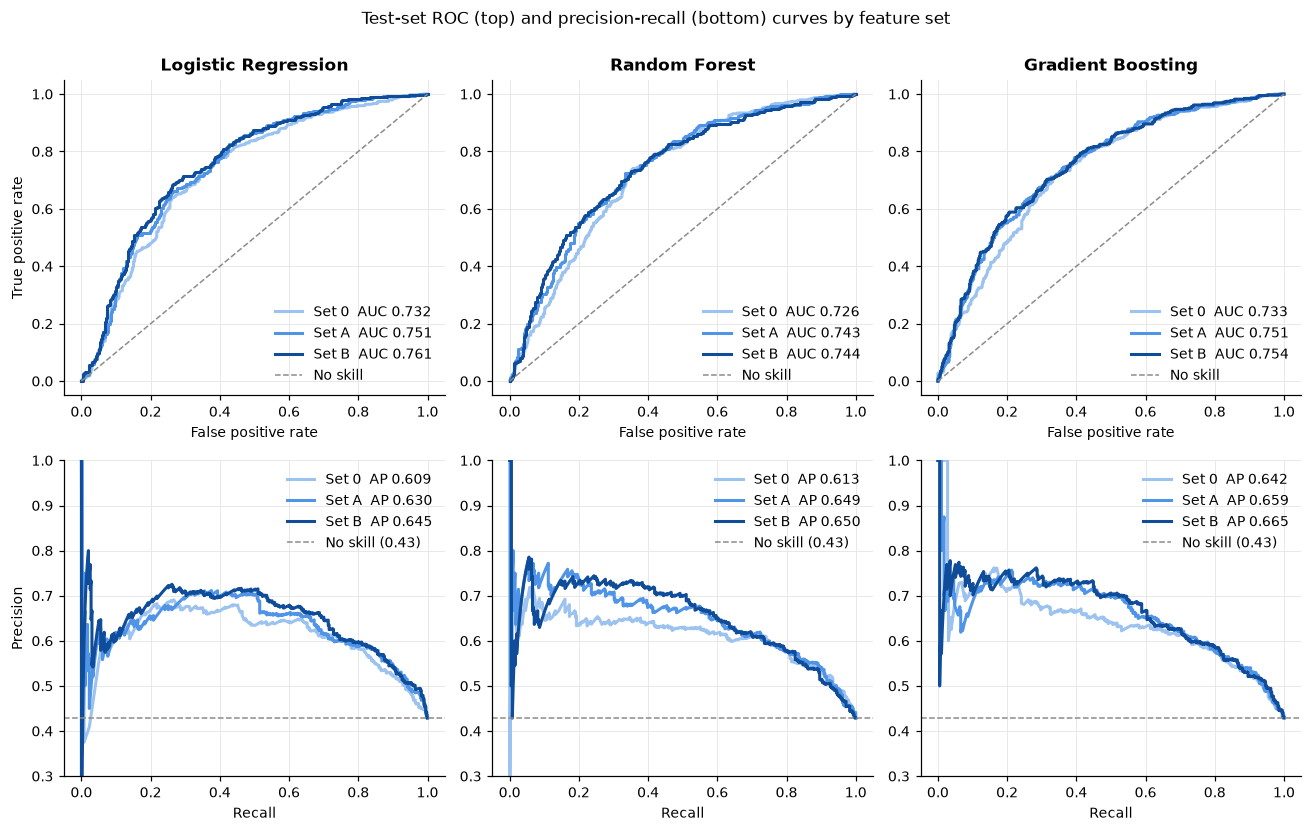

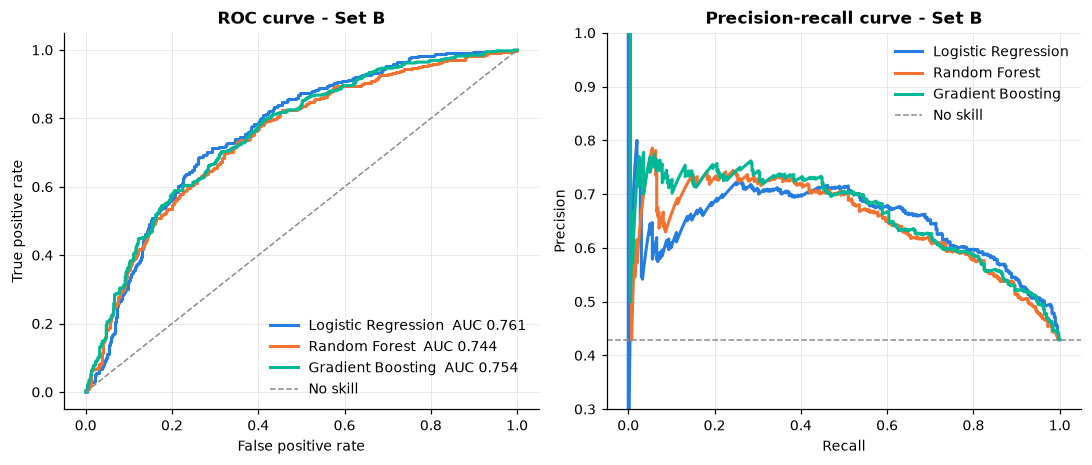

In [7]:
fig = plots.plot_roc_pr_by_set(preds, MODELS, SETS)
plots.save(fig, FIGS / "m4_03_roc_pr_curves_by_feature_set.png"); plt.show()

fig = plots.plot_roc_pr_by_model(preds, MODELS, "Set B")
plots.save(fig, FIGS / "m4_03_roc_pr_curves_set_b.png"); plt.show()

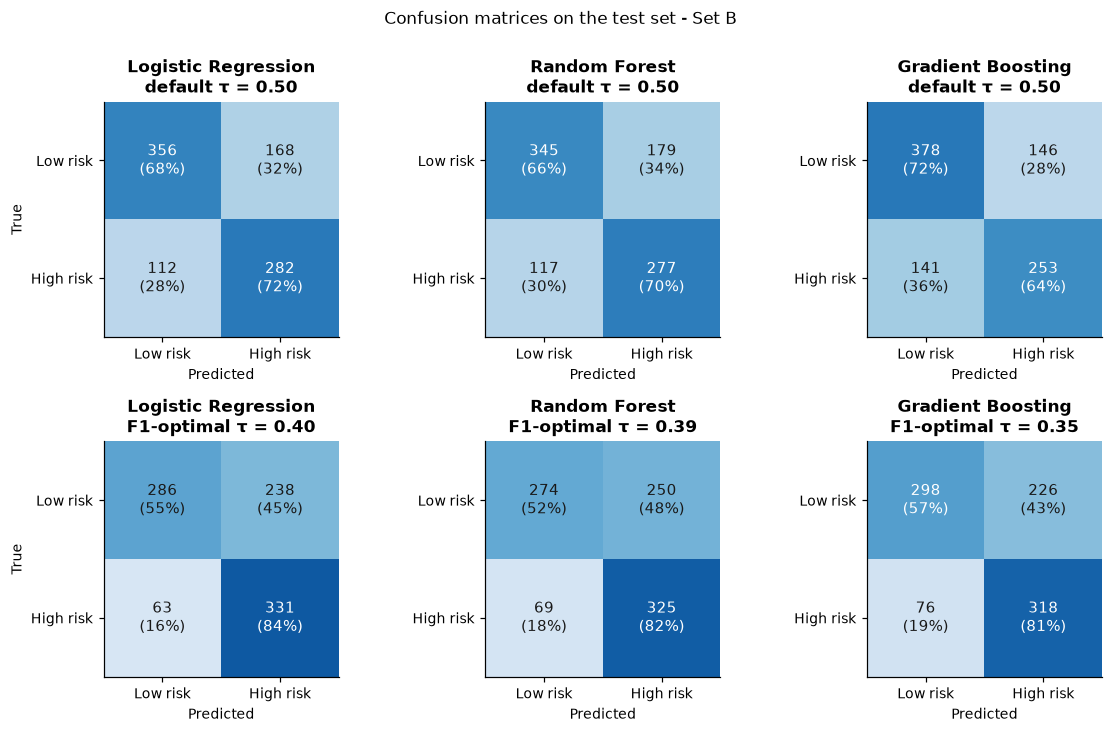

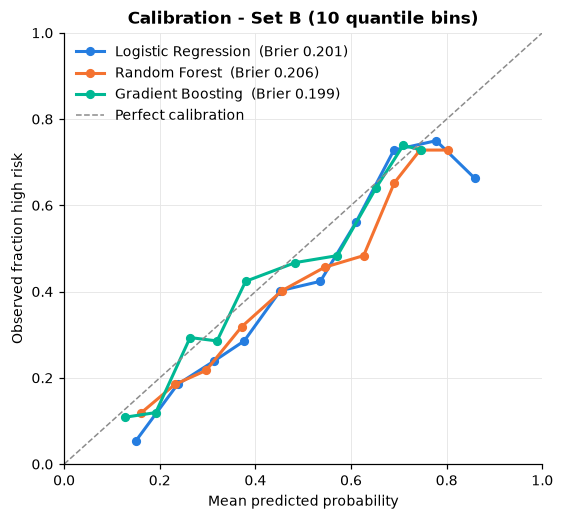

In [8]:
thr_b = {m: tau_f1[("Set B", m)] for m in MODELS}
fig = plots.plot_confusion_matrices(preds, MODELS, "Set B", thr_b)
plots.save(fig, FIGS / "m4_03_confusion_matrices_set_b.png"); plt.show()

brier_b = point[(point.feature_set == "Set B") & (point.threshold == "tau_F1")].set_index("model").brier
fig = plots.plot_calibration(preds, MODELS, "Set B", brier_b.to_dict())
plots.save(fig, FIGS / "m4_03_calibration_set_b.png"); plt.show()

## 6. Explainability (M4-05)
Three importance sources on **Set B** (the richest feature set) that fail in different ways:
1. **Logistic Regression odds ratios** - linear, per +1 SD (inputs are standardised in the pipeline).
2. **Random Forest Gini importance** - fitted on training data; biased towards continuous features.
3. **Permutation importance** on the test set (drop in ROC-AUC, R = 20) - model-agnostic, computed for every model.

A feature ranked high by all sources is a robust signal.

In [9]:
X_train_b, X_test_b, y_train_b, y_test_b = data["Set B"]
features_b = X_train_b.columns

odds = xai.lr_odds_ratios(pipes[("Set B", "Logistic Regression")], features_b)
gini = xai.tree_importance(pipes[("Set B", "Random Forest")], features_b)
gini_gb = xai.tree_importance(pipes[("Set B", "Gradient Boosting")], features_b)
perm = {m: xai.permutation_importance_auc(pipes[("Set B", m)], X_test_b, y_test_b) for m in MODELS}

odds.to_csv(TABLES / "feature_importance_lr_odds_ratios.csv", index=False)
gini.to_csv(TABLES / "feature_importance_rf_gini.csv", index=False)
pd.concat([p.assign(model=m) for m, p in perm.items()]).to_csv(
    TABLES / "feature_importance_permutation.csv", index=False)

ranks = xai.rank_table(
    lr_coef=odds.set_index("feature").coefficient,
    rf_gini=gini.set_index("feature").importance,
    gb_gini=gini_gb.set_index("feature").importance,
    **{f"perm_{m.split()[0].lower()}": p.set_index("feature").importance_mean.clip(lower=0) for m, p in perm.items()})
ranks.to_csv(TABLES / "feature_importance_rank_agreement.csv")
display(ranks.head(15))

,lr_coef,rf_gini,gb_gini,perm_logistic,perm_random,perm_gradient,mean_rank
feature,,,,,,,
age,2.0,1.0,1.0,2.0,1.0,1.0,1.333
mean_daily_mims,1.0,5.0,6.0,1.0,4.0,9.0,4.333
min_high_intensity,6.0,2.0,4.0,11.0,2.0,8.0,5.500
day_to_day_cv_mims,14.0,8.0,9.0,14.0,9.0,6.0,10.000
race_6,12.0,26.0,11.0,10.0,5.0,4.0,11.333
pca_score_3,4.0,12.0,18.0,3.0,28.0,12.0,12.833
mims_q3,29.0,6.0,5.0,30.5,3.0,5.0,13.083
mims_p90,34.5,4.0,2.0,30.5,8.0,2.0,13.500
mims_q2,10.0,17.0,13.0,6.0,28.0,18.0,15.333


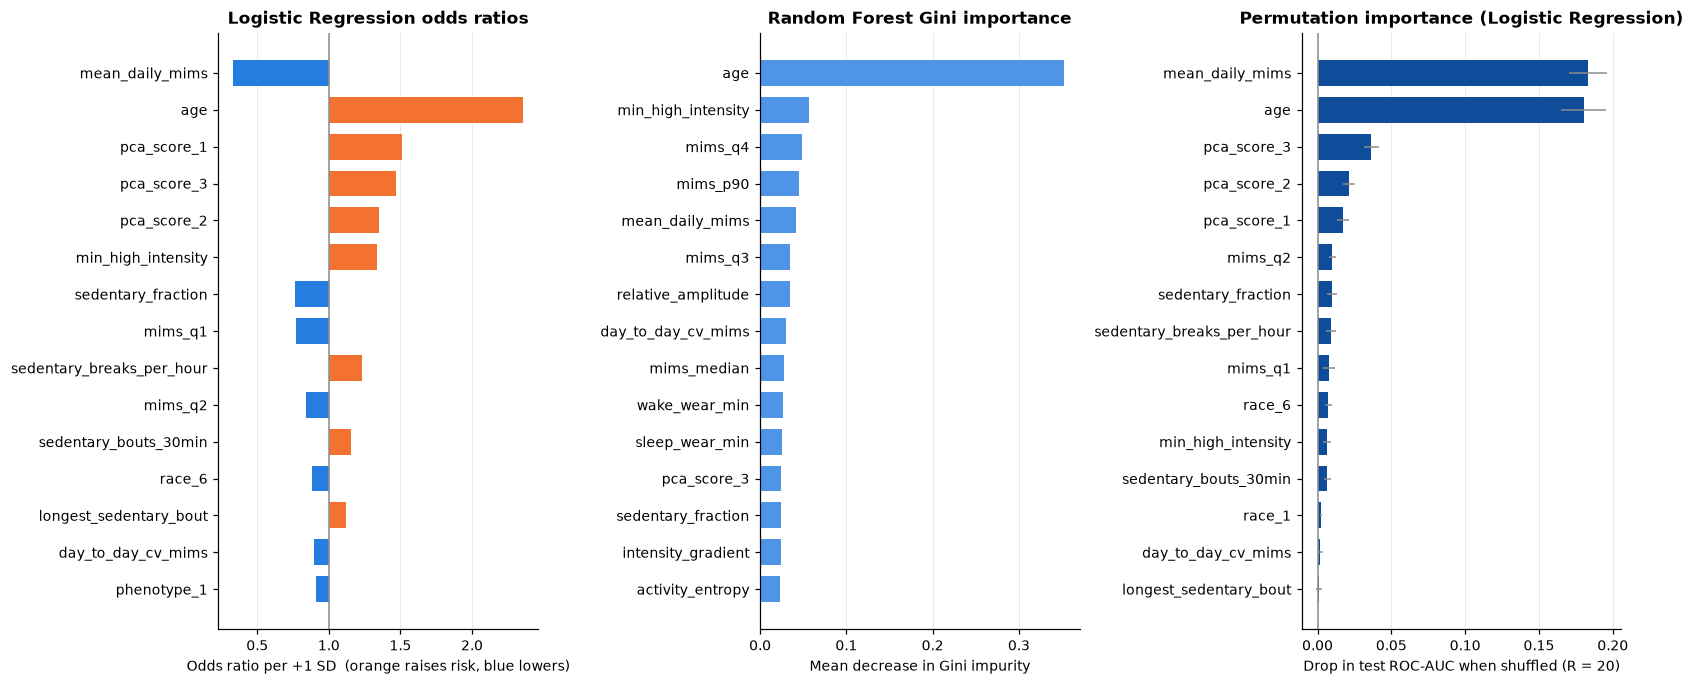

In [10]:
best_b = point[(point.feature_set == "Set B") & (point.threshold == "tau_F1")].set_index("model").roc_auc.idxmax()
fig = plots.plot_importance_panels(
    odds, gini, perm[best_b], top=15,
    titles=("Logistic Regression odds ratios", "Random Forest Gini importance",
            f"Permutation importance ({best_b})"))
plots.save(fig, FIGS / "m4_05_feature_importance.png"); plt.show()

,filter_mi,embedded_l1,both_methods
age,1.0,1.0,1.0
min_high_intensity,1.0,1.0,1.0
sedentary_breaks_per_hour,0.8,0.8,0.8
race_6,0.6,1.0,0.6
sedentary_bouts_30min,0.4,1.0,0.4
phenotype_1,0.4,0.6,0.4
female,0.2,0.8,0.2
race_7,0.2,0.8,0.2
smoking_current,0.2,0.8,0.2
phenotype_3,0.2,0.6,0.2


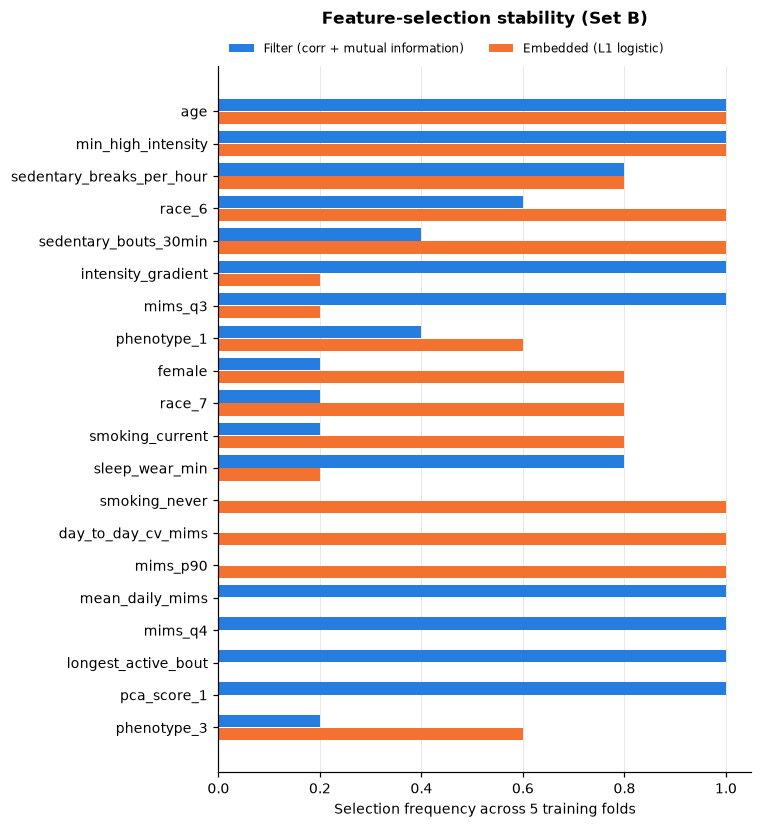

In [11]:
stability = xai.selection_stability(X_train_b, y_train_b)
stability.to_csv(TABLES / "feature_selection_stability.csv")
display(stability.head(15))
fig = plots.plot_selection_stability(stability, top=20)
plots.save(fig, FIGS / "m4_05_selection_stability.png"); plt.show()

## 7. Sensitivity analyses (M4-06, M4-07)
All three experiments use **Set B** and every model.

- **E4 - survey weights.** Primary models are unweighted (prediction, not population estimation). Here each model is refitted with
  `w_i = WTSAF2YR_i / 2` (fasting-subsample weight, two cycles combined), rescaled so positive weights have mean 1. Test performance is shown both unweighted and survey-weighted.
  418 participants (9.1%) have `WTSAF2YR = 0`: NHANES puts them outside the official fasting subsample and its guidelines exclude them from weighted analyses, so a weight of 0 removes them from the weighted fits and weighted scores only (see `n_train` / `n_test`).
- **E5 - cross-cycle transfer.** Tune + train on 2011-12, test on all of 2013-14 (and the reverse).
- **E6 - feature-group ablation.** *Adapted:* the proposal planned "single step algorithm vs. all five", but the cohort was built from
  NHANES `PAXMIN` (MIMS only), so no step-count columns exist. Instead each engineered feature group is removed in turn
  (5-fold CV on the training set) to test how much the result depends on one type of activity measure.

In [12]:
best_params = cv_summary.set_index(["feature_set", "model"]).best_params

e4 = pd.concat([sensitivity.survey_weighted_refit(m, best_params[("Set B", m)], *data["Set B"])
                for m in MODELS], ignore_index=True)
display(e4.pivot_table(index="model", columns=["training", "test_evaluation"], values="roc_auc"))

training            survey-weighted                 unweighted           
test_evaluation     survey-weighted unweighted survey-weighted unweighted
model                                                                    
Gradient Boosting             0.737      0.748           0.743      0.754
Logistic Regression           0.753      0.757           0.756      0.761
Random Forest                 0.724      0.738           0.736      0.744

In [13]:
e5 = pd.concat([sensitivity.cross_cycle_transfer(FEATURE_SET_FILES["Set B"], m) for m in MODELS],
               ignore_index=True)
display(e5.drop(columns=["y_proba", "y_true"]))

,model,direction,n_train,n_test,cv_auc_train_cycle,roc_auc,pr_auc,brier
0,Logistic Regression,2011-12 -> 2013-14,2294,2281,0.766,0.736,0.643,0.210
1,Logistic Regression,2013-14 -> 2011-12,2281,2294,0.750,0.768,0.667,0.196
2,Random Forest,2011-12 -> 2013-14,2294,2281,0.760,0.738,0.658,0.207
3,Random Forest,2013-14 -> 2011-12,2281,2294,0.746,0.755,0.670,0.200
4,Gradient Boosting,2011-12 -> 2013-14,2294,2281,0.764,0.743,0.661,0.203
5,Gradient Boosting,2013-14 -> 2011-12,2281,2294,0.758,0.765,0.680,0.194


In [14]:
e6 = pd.concat([sensitivity.feature_group_ablation(m, best_params[("Set B", m)], X_train_b, y_train_b)
                for m in MODELS], ignore_index=True)
display(e6.pivot(index="removed_group", columns="model", values="delta_auc"))

model,Gradient Boosting,Logistic Regression,Random Forest
removed_group,,,
(none: full Set B),0.000e+00,0.000e+00,0.000e+00
Basic activity,4.649e-04,5.655e-04,-1.181e-03
Intensity distribution,-2.633e-05,-6.368e-04,3.092e-03
Rhythm & variability,-4.193e-03,-2.601e-04,-3.930e-03
Sedentary behaviour,6.940e-04,-7.379e-04,5.885e-04
Unsupervised (PCA + k-means),-9.066e-04,-2.650e-03,1.839e-03


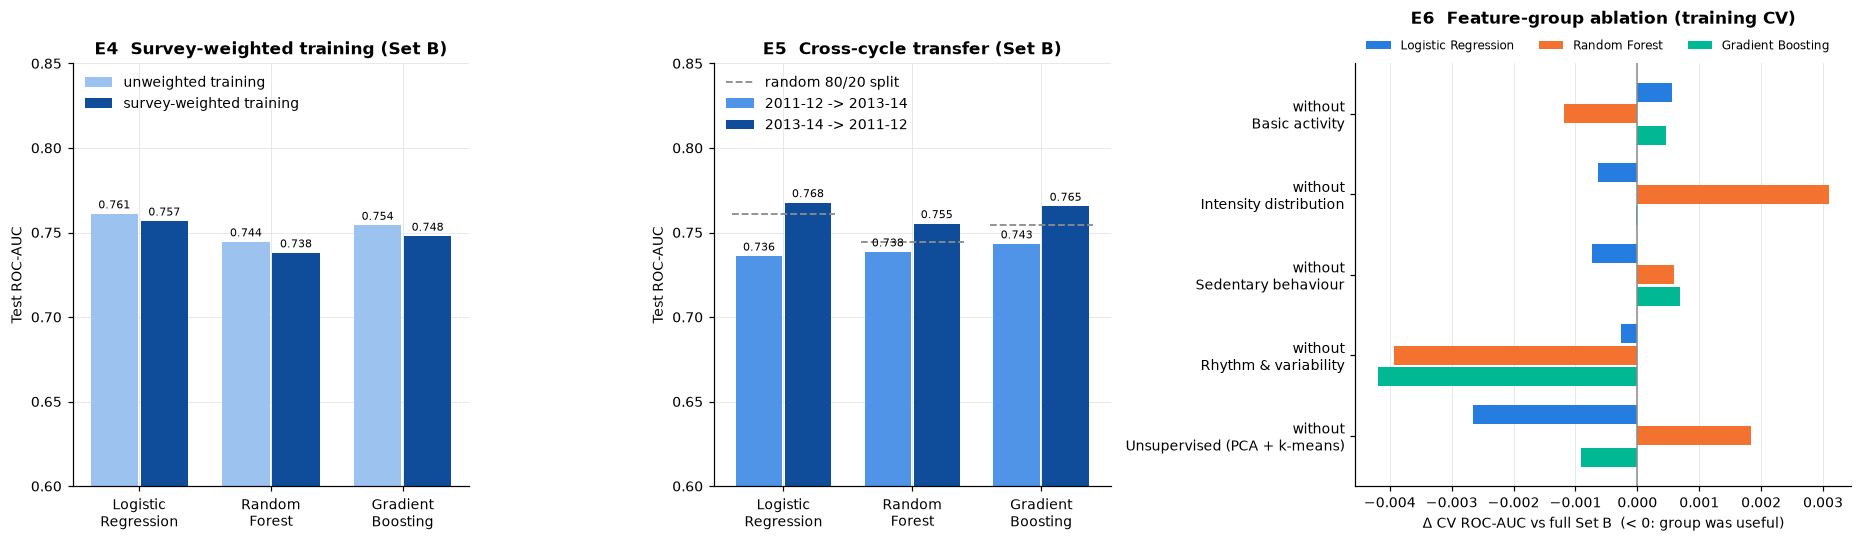

In [15]:
# One tidy table for all three experiments
sens = pd.concat([
    e4.assign(experiment="E4 survey weights",
              setting=lambda d: d.training + " training / " + d.test_evaluation + " test"),
    e5.drop(columns=["y_proba", "y_true"]).assign(experiment="E5 cross-cycle", setting=lambda d: d.direction),
    e6.rename(columns={"cv_roc_auc": "roc_auc"}).assign(
        experiment="E6 feature-group ablation (train CV)", setting=lambda d: "removed: " + d.removed_group),
], ignore_index=True)
cols = ["experiment", "model", "setting", "roc_auc", "pr_auc", "brier", "delta_auc", "n_train", "n_test", "cv_std"]
sens = sens[[c for c in cols if c in sens.columns]]
sens.to_csv(TABLES / "sensitivity_analysis_results.csv", index=False)

main_auc_b = point[(point.feature_set == "Set B") & (point.threshold == "tau_F1")].set_index("model").roc_auc.to_dict()
fig = plots.plot_sensitivity(e4, e5, e6, MODELS, main_auc_b)
plots.save(fig, FIGS / "m4_07_sensitivity_analyses.png"); plt.show()

## 8. Files written

In [16]:
for folder in (TABLES, FIGS):
    for f in sorted(folder.glob("m4_*.png" if folder == FIGS else "*.csv")):
        print(f"{f.relative_to(ROOT).as_posix():60s} {f.stat().st_size / 1024:7.1f} KB")

reports/tables/feature_importance_lr_odds_ratios.csv             1.8 KB
reports/tables/feature_importance_permutation.csv                7.6 KB
reports/tables/feature_importance_rank_agreement.csv             2.1 KB
reports/tables/feature_importance_rf_gini.csv                    1.3 KB
reports/tables/feature_selection_stability.csv                   1.0 KB
reports/tables/model_performance_metrics.csv                    15.4 KB
reports/tables/model_performance_summary.csv                     1.9 KB
reports/tables/sensitivity_analysis_results.csv                  5.2 KB
reports/tables/statistical_tests.csv                             2.8 KB
reports/figures/m4_03_calibration_set_b.png                    163.0 KB
reports/figures/m4_03_confusion_matrices_set_b.png             332.0 KB
reports/figures/m4_03_roc_pr_curves_by_feature_set.png         588.5 KB
reports/figures/m4_03_roc_pr_curves_set_b.png                  268.4 KB
reports/figures/m4_04_pr_auc_forest_plot.png                   1

## 9. Key findings (M4-08)

**RQ1 - How well can classical classifiers predict risk?** Moderately well. On the 918 held-out participants, Set B models reach
ROC-AUC **0.744-0.761** (95% CIs about +/-0.03) against 0.50 for the majority-class baseline, and PR-AUC **0.645-0.665** against a no-skill 0.43.
At the F1-optimal threshold the best model (Logistic Regression) finds **84% of high-risk people** (recall 0.84, precision 0.58, F1 0.69).
This matches the proposal's expectation of *moderate* discrimination: the models never see waist, blood pressure or blood tests.

**Model choice.** The linear model is as good as or better than the ensembles: Logistic Regression beats Random Forest
(DeLong p = 0.012) and is level with Gradient Boosting (p = 0.23). Non-linear interactions add no detectable signal at n = 3,657.
All models are reasonably calibrated (Brier 0.199-0.206).

**RQ2 - Value of wearable data.**
- Set 0 -> Set A (adding basic activity) raises ROC-AUC by **+0.017 to +0.019 for every model**; significant by DeLong for all three
  (p <= 0.045) and by paired bootstrap for LR and GB.
- Set A -> Set B (engineered features) helps only Logistic Regression (+0.010, p = 0.013); for RF and GB the gain is not significant.

**RQ3 - Which features matter, and is the ranking stable?** Age is the strongest single predictor under every method.
Among activity features, **overall activity volume (mean daily MIMS), minutes of high-intensity activity, upper MIMS percentiles
(q3, p90), day-to-day variability and the 24-h profile PCA scores** rank high across LR coefficients, tree importance and
permutation importance. `min_high_intensity` and `sedentary_breaks_per_hour` are selected in >= 80% of folds by **both** the filter
and the embedded selector. Higher activity lowers predicted risk (LR odds ratio for mean daily MIMS = 0.33 per SD).

**Robustness.**
- **E4:** survey-weighted training changes test ROC-AUC by < 0.01 for every model, so the conclusions are not an artefact of the sampling design.
- **E5:** models trained on one NHANES cycle reach ROC-AUC 0.736-0.768 on the other, close to the random-split result, so they transfer over time.
- **E6:** removing any single engineered feature group changes CV ROC-AUC by at most 0.004. The activity information is **redundant
  across groups** (they are all derived from the same MIMS signal), which explains why Set B adds little over Set A for the ensembles.

**Limitations to report.** (1) 3 of the 8 planned classifiers were trained by the progress-evaluation stage. (2) The cohort was built from
NHANES `PAXMIN` (MIMS only), so step-count features and the planned step-algorithm experiment could not be run; E6 was adapted.
(3) 418 participants have zero fasting weight and are excluded from the weighted analysis only. (4) Results describe screening value, not diagnosis.